# Table I and Conditional Execution: Single-Checkpoint CPU Evaluation

This optional notebook uses 16 PT checkpoints: one checkpoint for each of eight model configurations and two training years, plus four LR models. It generates LR features, CC matrices and USP inputs directly from raw `.tim` IQ in memory. No feature cache, saved prediction, or historical result is loaded or written.

The default accuracy check selects 32 samples per class (256 samples per evaluation population), evenly across SNR. These are single-checkpoint sample accuracies, not the original five-seed statistics or full-dataset accuracies. Set `SAMPLES_PER_CLASS` in Section 1 to change the sample count. CPU measurements use one thread and freshly loaded model weights.

Raw data must be available at `../../CSPB.ML_dataset` relative to the project root; split manifests come from `group_split_70_5_25alter/splits`. Dataset labels and split CSVs are input metadata, not historical results. Only weights, helper code and this notebook are shipped for CPU evaluation.

For mixed-CC baselines, non-QPSK-like inputs use class-specific CC patterns with true parameters; QPSK-like inputs use blind estimates. FFT features and Rs/CFO use P96-clipped z, while CC uses unclipped x_processed. FFT/SSCA prefixes describe the Table I frontend cost budgets. Section 10 independently times the full raw-IQ pipeline on a small test sample. Tables and figures are retained only in this notebook.

## 1. Relative Paths, Assets, and Integrity

In [1]:
from pathlib import Path
import os, sys, shutil, subprocess
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd()
if (cwd / 'cpu_latency_comparison' / 'table1_reproduction_core.py').is_file():
    PROJECT = cwd
elif (cwd / 'table1_reproduction_core.py').is_file() and cwd.name == 'cpu_latency_comparison':
    PROJECT = cwd.parent
else:
    raise FileNotFoundError('Run this notebook from the project root or the cpu_latency_comparison directory.')
HERE = PROJECT / 'cpu_latency_comparison'
ASSETS = HERE / 'table1_reproduction_assets'
sys.path.insert(0, str(HERE))
import table1_reproduction_core as core
torch.set_num_threads(1)

inventory = core.weight_inventory(ASSETS)
inventory['kind'] = inventory.path.str.split('/').str[1]
assert inventory.path.str.endswith('.pt').sum() == 16
assert inventory.path.str.endswith('.joblib').sum() == 4
SAMPLES_PER_CLASS = 32
assert not (ASSETS/'inputs').exists()
native_kernels = sorted(path.name for path in (ASSETS/'native').glob('*.so'))
assert native_kernels == ['spl_boi_exact.so','spl_cc_current.so','spl_fft3_exact.so']
display(inventory.groupby('kind').agg(files=('path','size'), size_MiB=('bytes',lambda x:x.sum()/2**20)))
print('Accuracy samples per class and population:', SAMPLES_PER_CLASS)
print('Local native kernels:', native_kernels)
print('All paths are relative to the project directory; no historical result files were read.')

,files,size_MiB
kind,,
lr,4,0.018805
matched_cap8,2,9.795990
matched_lite8,2,0.891708
mixed_cc,8,21.341667
proposed_lite4,2,0.912361
usp,2,21.357956


Accuracy samples per class and population: 32
Local native kernels: ['spl_boi_exact.so', 'spl_cc_current.so', 'spl_fft3_exact.so']
All paths are relative to the project directory; no historical result files were read.


## 2. Operation Formulas and Model Architecture Checks

In [2]:
N, Nprime, P, K = 32768, 64, 7, 18
FFT3 = 8*N + 3*N*int(np.log2(N))
CC = P*N + K*N*int(np.log2(N))
SSCA = N*Nprime*(int(np.log2(Nprime))+int(np.log2(N))) + 4*N*Nprime + 3*N + N*int(np.log2(N))
USP_FRONTEND = 8*N + 4*N*int(np.log2(N))
LR5, LR8 = 32*5, 32*8
assert (FFT3, CC, SSCA, USP_FRONTEND) == (1736704, 9076736, 53018624, 2228224)

architecture = core.architecture_counts()
assert architecture.loc['CC_CAP8','total_macs'] == 34900152
assert architecture.loc['CAPNetLite4','total_macs'] == 14382580
assert architecture.loc['CAPNetLite8','total_macs'] == 14382660
assert architecture.loc['IQ_BOI_USP8','total_macs'] == 7428120704
primitives = pd.DataFrame([
    ('FFT3 frontend','8N+3N log2(N)',FFT3), ('CC','PN+KN log2(N)',CC),
    ('SSCA frontend',"NN'(log2(N')+log2(N))+4NN'+3N+N log2(N)",SSCA),
    ('USP frontend','8N+4N log2(N)',USP_FRONTEND),
    ('LR32 five-class routing','32×5',LR5), ('LR32 eight-class direct classification','32×8',LR8),
], columns=['Module','Expression','Operations'])
display(primitives)
display(architecture)

,Module,Expression,Operations
0,FFT3 frontend,8N+3N log2(N),1736704
1,CC,PN+KN log2(N),9076736
2,SSCA frontend,NN'(log2(N')+log2(N))+4NN'+3N+N log2(N),53018624
3,USP frontend,8N+4N log2(N),2228224
4,LR32 five-class routing,32×5,160
5,LR32 eight-class direct classification,32×8,256


,conv_macs,linear_macs,total_macs,parameters
CC_CAP8,34811392,88760,34900152,1267936
CAPNetLite4,14382500,80,14382580,111064
CAPNetLite8,14382500,160,14382660,111148
IQ_BOI_USP8,7428112384,8320,7428120704,2757816


## 3. Generate Inputs from Raw IQ and Evaluate One Checkpoint per Configuration

In [3]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Inference device:', device)
inputs = core.generate_inputs(PROJECT, ASSETS, samples_per_class=SAMPLES_PER_CLASS)
per_seed_accuracy, accuracy_summary, routing = core.evaluate_accuracies(ASSETS, device, inputs)
assert len(per_seed_accuracy) == 28  # One checkpoint for each method and train/test pair
assert len(accuracy_summary) == 28
display(accuracy_summary.pivot(index=['method','train_year'], columns='test_year',
                               values=['accuracy_percent','n']))
display(routing)

Inference device: cuda:0


Raw IQ inputs generated in memory: 2018 same_test, 256 samples


Raw IQ inputs generated in memory: 2018 external_all, 256 samples


Raw IQ inputs generated in memory: 2022 same_test, 256 samples


Raw IQ inputs generated in memory: 2022 external_all, 256 samples


...

usp(sample) 2018->2022: one weight complete


usp(sample) 2022->2018: one weight complete


usp(sample) 2022->2022: one weight complete


accuracy_percent                 n       
test_year                                2018       2022   2018   2022
method            train_year                                          
cap8_always       2018              90.625000  91.406250  256.0  256.0
                  2022              87.500000  96.484375  256.0  256.0
direct            2018              85.937500  77.343750  256.0  256.0
                  2022              75.781250  82.421875  256.0  256.0
lite8_always      2018              89.843750  92.968750  256.0  256.0
                  2022              88.671875  95.703125  256.0  256.0
proposed          2018              91.015625  92.578125  256.0  256.0
                  2022              89.062500  96.093750  256.0  256.0
ssca_lite8_always 2018              90.625000  93.750000  256.0  256.0
                  2022              88.281250  96.093750  256.0  256.0
ssca_reference    2018              90.234375  90.625000  256.0  256.0
                  2022              88.671875  94.921875  256.0  256.0
usp               2018              87.109375  82.031250  256.0  256.0
                  2022              83.984375  92.968750  256.0  256.0

,train_year,test_year,n,predicted_refinement_rate,true_qpsklike_rate,true_qpsklike_n,other_n,tpr,fpr,false_family_rejections,unnecessary_refinements
0,2018,2018,256,0.500000,0.5,128,128,1.000000,0.0,0,0
1,2018,2022,256,0.500000,0.5,128,128,1.000000,0.0,0,0
2,2022,2018,256,0.496094,0.5,128,128,0.992188,0.0,1,0
3,2022,2022,256,0.500000,0.5,128,128,1.000000,0.0,0,0


## 4. Table I Costs, Fresh CPU Timing, and the Two Hierarchical Paths

The scalar frontend/CC proxies and classifiers are timed again in this run. CPU values vary with hardware, system load, and software versions; operation counts remain fixed.

In [4]:
scalar_timing = core.fresh_scalar_timings(PROJECT).set_index('stage')
classifier_timing = core.fresh_classifier_timings(ASSETS)
nn_ms = classifier_timing.groupby('component').median_ms.mean()

CAP = int(architecture.loc['CC_CAP8','total_macs'])
LITE4 = int(architecture.loc['CAPNetLite4','total_macs'])
LITE8 = int(architecture.loc['CAPNetLite8','total_macs'])
USP_CNN = int(architecture.loc['IQ_BOI_USP8','total_macs'])
REF = SSCA + CC + CAP
T_REF = scalar_timing.loc['ssca_frontend','scalar_proxy_ms'] + scalar_timing.loc['cc_full','scalar_proxy_ms'] + nn_ms.ref4_cap8
T_F = scalar_timing.loc['fft3_frontend','scalar_proxy_ms']
T_CC = scalar_timing.loc['cc_full','scalar_proxy_ms']
B, R = FFT3 + LR5, CC + LITE4
T_B, T_R = T_F + nn_ms.route5, T_CC + nn_ms.proposed_lite4

def cost_row(method, label, preprocessing, classifier, latency):
    total = preprocessing + classifier
    return dict(method=method, label=label, pre_processing_ops=int(preprocessing),
                classifier_ops=int(classifier), total_ops=int(total),
                cpu_latency_proxy_ms=float(latency), operation_speedup=REF/total,
                cpu_speedup=T_REF/latency)

q_table = 0.5
table_metrics = pd.DataFrame([
    cost_row('usp','I/Q–BOI–USP',USP_FRONTEND,USP_CNN,
             scalar_timing.loc['usp_frontend','scalar_proxy_ms']+nn_ms.usp_cnn_core),
    cost_row('ssca_reference','SSCA–CC–CAP8',SSCA+CC,CAP,T_REF),
    cost_row('cap8_always','FFT–CC–CAP8',FFT3+CC,CAP,T_F+T_CC+nn_ms.ref4_cap8),
    cost_row('ssca_lite8_always','SSCA–CC–CNN8',SSCA+CC,LITE8,
             scalar_timing.loc['ssca_frontend','scalar_proxy_ms']+T_CC+nn_ms.control_lite8),
    cost_row('lite8_always','FFT–CC–CNN8',FFT3+CC,LITE8,T_F+T_CC+nn_ms.control_lite8),
    cost_row('direct','Direct FFT–LR32',FFT3,LR8,T_F+nn_ms.direct8),
    cost_row('proposed','Hierarchical method, q=0.5',FFT3+q_table*CC,LR5+q_table*LITE4,T_B+q_table*T_R),
])
paths = pd.DataFrame([
    cost_row('non_qpsklike','Non-QPSK-like path',FFT3,LR5,T_B),
    cost_row('qpsklike','QPSK-like path',FFT3+CC,LR5+LITE4,T_B+T_R),
])
table1 = accuracy_summary.merge(table_metrics, on='method', validate='many_to_one')
display(scalar_timing.reset_index())
display(classifier_timing)
display(table_metrics)
display(paths)
display(table1.pivot(index=['method','label','train_year'], columns='test_year',
                     values=['accuracy_percent']))

scalar proxy ssca_frontend: 20.270003 ms


scalar proxy fft3_frontend: 0.668556 ms


scalar proxy usp_frontend: 0.803685 ms


scalar proxy cc_full: 3.466792 ms


CPU 2018 ref4_cap8: 11.037719 ms


...

,stage,operation_budget,logical_inferences,scheduled_ops,scalar_proxy_ms,trials_seconds,checksum,pinned_core
0,ssca_frontend,53018624,29,1537540096,20.270003,"[0.5996620859999999, 0.587830073]",4.115179,0
1,fft3_frontend,1736704,864,1500512256,0.668556,"[0.579720515, 0.577632077]",4.115179,0
2,usp_frontend,2228224,674,1501822976,0.803685,"[0.56109409, 0.5416836309999999]",4.115179,0
3,cc_full,9076736,166,1506738176,3.466792,"[0.575487549, 0.5800946469999999]",4.115179,0


,year,component,median_ms,mean_ms,trial_ms,repeats
0,2018,ref4_cap8,11.037719,11.071022,"[11.16819731, 11.007150639999999, 11.037719]",100
1,2018,control_lite8,2.214247,2.224312,"[2.246647355, 2.2142467999999997, 2.21204097]",200
2,2018,proposed_lite4,2.211164,2.212277,"[2.21116369, 2.218942, 2.20672628]",200
3,2018,usp_cnn_core,431.151808,431.747051,"[430.9780356666667, 433.1113096666666, 431.151...",3
4,2018,route5,0.039522,0.039710,"[0.039522322400000004, 0.040320446600000004, 0...",5000
5,2018,direct8,0.039892,0.039832,"[0.0400083734, 0.0398919104, 0.0395962082]",5000
6,2022,ref4_cap8,8.074291,8.103878,"[8.19344613, 8.07429059, 8.043898050000001]",100
7,2022,control_lite8,2.214124,2.214516,"[2.214124295, 2.21595409, 2.213468325]",200
8,2022,proposed_lite4,2.233149,2.226733,"[2.234113715, 2.233148525, 2.21293807]",200
9,2022,usp_cnn_core,441.495211,441.411922,"[440.513751, 442.226803, 441.49521066666665]",3


,method,label,pre_processing_ops,classifier_ops,total_ops,cpu_latency_proxy_ms,operation_speedup,cpu_speedup
0,usp,I/Q–BOI–USP,2228224,7428120704,7430348928,437.127194,0.013054,0.076163
1,ssca_reference,SSCA–CC–CAP8,62095360,34900152,96995512,33.292800,1.000000,1.000000
2,cap8_always,FFT–CC–CAP8,10813440,34900152,45713592,13.691353,2.121809,2.431666
3,ssca_lite8_always,SSCA–CC–CNN8,62095360,14382660,76478020,25.950981,1.268280,1.282911
4,lite8_always,FFT–CC–CNN8,10813440,14382660,25196100,6.349534,3.849624,5.243346
5,direct,Direct FFT–LR32,1736704,256,1736960,0.708479,55.842110,46.991912
6,proposed,"Hierarchical method, q=0.5",6275072,7191450,13466522,3.552834,7.202714,9.370772


,method,label,pre_processing_ops,classifier_ops,total_ops,cpu_latency_proxy_ms,operation_speedup,cpu_speedup
0,non_qpsklike,Non-QPSK-like path,1736704,160,1736864,0.708360,55.845197,46.999843
1,qpsklike,QPSK-like path,10813440,14382740,25196180,6.397308,3.849612,5.204189


accuracy_percent  \
test_year                                                           2018   
method            label                      train_year                    
cap8_always       FFT–CC–CAP8                2018              90.625000   
                                             2022              87.500000   
direct            Direct FFT–LR32            2018              85.937500   
                                             2022              75.781250   
lite8_always      FFT–CC–CNN8                2018              89.843750   
                                             2022              88.671875   
proposed          Hierarchical method, q=0.5 2018              91.015625   
                                             2022              89.062500   
ssca_lite8_always SSCA–CC–CNN8               2018              90.625000   
                                             2022              88.281250   
ssca_reference    SSCA–CC–CAP8               2018              90.234375   
                                             2022              88.671875   
usp               I/Q–BOI–USP                2018              87.109375   
                                             2022              83.984375   

                                                                    
test_year                                                     2022  
method            label                      train_year             
cap8_always       FFT–CC–CAP8                2018        91.406250  
                                             2022        96.484375  
direct            Direct FFT–LR32            2018        77.343750  
                                             2022        82.421875  
lite8_always      FFT–CC–CNN8                2018        92.968750  
                                             2022        95.703125  
proposed          Hierarchical method, q=0.5 2018        92.578125  
                                             2022        96.093750  
ssca_lite8_always SSCA–CC–CNN8               2018        93.750000  
                                             2022        96.093750  
ssca_reference    SSCA–CC–CAP8               2018        90.625000  
                                             2022        94.921875  
usp               I/Q–BOI–USP                2018        82.031250  
                                             2022        92.968750

## 5. General Expression in q and Speedup Decomposition

Let $q$ be the probability that a sample enters the refinement branch:

$$\bar C(q)=C_F+C_L+qC_R,$$
$$S_{\rm total}(q)=\frac{C_{\rm SSCA-CAP}}{C_F+C_L+qC_R},\qquad
S_{\rm cond}(q)=\frac{C_F+C_L+C_R}{C_F+C_L+qC_R}.$$

The second ratio compares always-on and conditional execution using the same modules, so $S_{\rm cond}(1)=1$.

In [5]:
q_grid = np.linspace(0,1,501)
curve_frames = []
for name, refinement, network_ms in (
    ('CAP8',CC+CAP,nn_ms.ref4_cap8), ('Lite8',CC+LITE8,nn_ms.control_lite8),
    ('Lite4',R,nn_ms.proposed_lite4)):
    costs = B + q_grid*refinement
    times = T_B + q_grid*(T_CC+network_ms)
    curve_frames.append(pd.DataFrame(dict(classifier=name,q=q_grid,expected_ops=costs,
        overall_operation_speedup=REF/costs,
        conditional_only_operation_speedup=(B+refinement)/costs,
        hybrid_latency_proxy_ms=times, overall_hybrid_cpu_speedup=T_REF/times)))
q_curves = pd.concat(curve_frames,ignore_index=True)
fft_factor = (SSCA+CC+CAP)/(FFT3+CC+CAP)
classifier_factor = (FFT3+CC+CAP)/(FFT3+CC+LITE4)
scheduling_factor = (FFT3+CC+LITE4)/(FFT3+LR5+0.5*(CC+LITE4))
factors = pd.DataFrame([dict(fft_substitution=fft_factor, cap8_to_lite4=classifier_factor,
    conditional_scheduling_including_router=scheduling_factor,
    pure_conditional_same_router=(B+R)/(B+0.5*R), overall=REF/(B+0.5*R))])
assert np.isclose(fft_factor*classifier_factor*scheduling_factor,factors.overall.iloc[0])
display(factors)
display(q_curves.loc[q_curves.q.isin([0,.25,.5,.75,1])])

,fft_substitution,cap8_to_lite4,conditional_scheduling_including_router,pure_conditional_same_router,overall
0,2.121809,1.814318,1.871012,1.871024,7.202714


,classifier,q,expected_ops,overall_operation_speedup,conditional_only_operation_speedup,hybrid_latency_proxy_ms,overall_hybrid_cpu_speedup
0,CAP8,0.00,1736864.0,55.845197,26.319707,0.708360,46.999843
125,CAP8,0.25,12731086.0,7.618793,3.590719,3.964059,8.398664
250,CAP8,0.50,23725308.0,4.088272,1.926793,7.219758,4.611345
375,CAP8,0.75,34719530.0,2.793687,1.316658,10.475458,3.178171
500,CAP8,1.00,45713752.0,2.121802,1.000000,13.731157,2.424617
501,Lite8,0.00,1736864.0,55.845197,14.506755,0.708360,46.999843
626,Lite8,0.25,7601713.0,12.759691,3.314550,2.128604,15.640671
751,Lite8,0.50,13466562.0,7.202693,1.871024,3.548849,9.381296
876,Lite8,0.75,19331411.0,5.017508,1.303384,4.969093,6.699975
1001,Lite8,1.00,25196260.0,3.849600,1.000000,6.389338,5.210681


## 6. Matched CAP8/Lite8 × Always-On/Conditional Controls

In [6]:
control_per_seed, controls = core.evaluate_matched_controls(ASSETS, device, inputs)
assert len(control_per_seed) == 16 and len(controls) == 16
display(controls)
del inputs  # Release generated IQ/features; nothing is saved to disk.

matched controls 2018->2018: one paired weight complete


matched controls 2018->2022: one paired weight complete


matched controls 2022->2018: one paired weight complete


matched controls 2022->2022: one paired weight complete


,method,train_year,test_year,accuracy_percent,n_seeds,n,predicted_refinement_rate
0,cap8_always,2018,2018,88.281250,1,256,0.500000
1,cap8_gated,2018,2018,89.843750,1,256,0.500000
2,lite8_always,2018,2018,88.671875,1,256,0.500000
3,lite8_gated,2018,2018,89.453125,1,256,0.500000
4,cap8_always,2018,2022,90.625000,1,256,0.500000
5,cap8_gated,2018,2022,91.015625,1,256,0.500000
6,lite8_always,2018,2022,92.968750,1,256,0.500000
7,lite8_gated,2018,2022,93.359375,1,256,0.500000
8,cap8_always,2022,2018,87.890625,1,256,0.496094
9,cap8_gated,2022,2018,89.062500,1,256,0.496094


## 7. Observed Routing, Class-Prior Sensitivity, and Plots

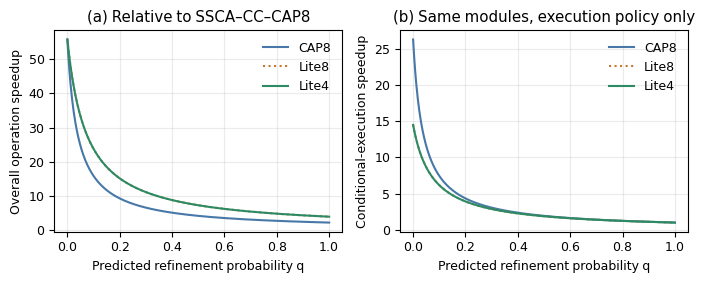

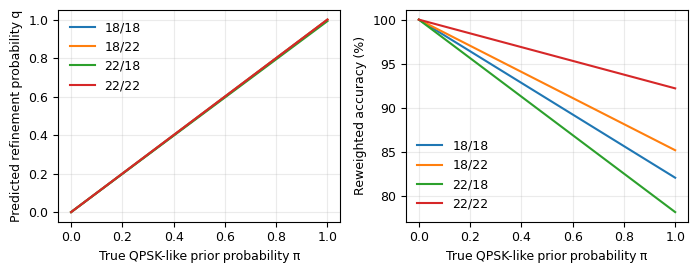

,train_year,test_year,true_family_prior,q,accuracy,expected_ops,overall_operation_speedup,conditional_only_operation_speedup
0,2018,2018,0.00,0.000000,1.000000,1.736864e+06,55.845197,14.506709
25,2018,2018,0.25,0.250000,0.955078,7.601693e+06,12.759725,3.314548
50,2018,2018,0.50,0.500000,0.910156,1.346652e+07,7.202714,1.871024
75,2018,2018,0.75,0.750000,0.865234,1.933135e+07,5.017524,1.303384
100,2018,2018,1.00,1.000000,0.820312,2.519618e+07,3.849612,1.000000
101,2018,2022,0.00,0.000000,1.000000,1.736864e+06,55.845197,14.506709
126,2018,2022,0.25,0.250000,0.962891,7.601693e+06,12.759725,3.314548
151,2018,2022,0.50,0.500000,0.925781,1.346652e+07,7.202714,1.871024
176,2018,2022,0.75,0.750000,0.888672,1.933135e+07,5.017524,1.303384
201,2018,2022,1.00,1.000000,0.851562,2.519618e+07,3.849612,1.000000


In [7]:
prior_rows=[]
for route in routing.itertuples(index=False):
    subset = per_seed_accuracy.loc[(per_seed_accuracy.method=='proposed') &
        (per_seed_accuracy.train_year==route.train_year) &
        (per_seed_accuracy.test_year==route.test_year)]
    acc_q=float(subset.qpsklike_accuracy.mean()); acc_o=float(subset.other_accuracy.mean())
    for pi in np.linspace(0,1,101):
        q = pi*route.tpr+(1-pi)*route.fpr
        prior_rows.append(dict(train_year=route.train_year,test_year=route.test_year,
            true_family_prior=pi,q=q,accuracy=pi*acc_q+(1-pi)*acc_o,
            expected_ops=B+q*R,overall_operation_speedup=REF/(B+q*R),
            conditional_only_operation_speedup=(B+R)/(B+q*R)))
prior = pd.DataFrame(prior_rows)

plt.rcParams.update({'font.family':['Droid Sans Fallback','DejaVu Sans'],
                     'font.size':9,'pdf.fonttype':42,'ps.fonttype':42})
colors={'CAP8':'#4878A8','Lite8':'#C27931','Lite4':'#2C8B64'}
fig,axes=plt.subplots(1,2,figsize=(7.05,2.9),sharex=True)
for name,group in q_curves.groupby('classifier',sort=False):
    style=':' if name=='Lite8' else '-'
    axes[0].plot(group.q,group.overall_operation_speedup,label=name,color=colors[name],linestyle=style)
    axes[1].plot(group.q,group.conditional_only_operation_speedup,label=name,color=colors[name],linestyle=style)
axes[0].set(xlabel='Predicted refinement probability q',ylabel='Overall operation speedup',title='(a) Relative to SSCA–CC–CAP8')
axes[1].set(xlabel='Predicted refinement probability q',ylabel='Conditional-execution speedup',title='(b) Same modules, execution policy only')
for ax in axes: ax.grid(alpha=.25); ax.legend(frameon=False)
fig.tight_layout(); plt.show()

fig,axes=plt.subplots(1,2,figsize=(7.05,2.8))
for (train,test),group in prior.groupby(['train_year','test_year']):
    label=f'{str(train)[-2:]}/{str(test)[-2:]}'
    axes[0].plot(group.true_family_prior,group.q,label=label)
    axes[1].plot(group.true_family_prior,100*group.accuracy,label=label)
axes[0].set(xlabel='True QPSK-like prior probability π',ylabel='Predicted refinement probability q')
axes[1].set(xlabel='True QPSK-like prior probability π',ylabel='Reweighted accuracy (%)')
for ax in axes: ax.grid(alpha=.25); ax.legend(frameon=False)
fig.tight_layout(); plt.show()
display(prior.loc[prior.true_family_prior.isin([0,.25,.5,.75,1])])

## 8. Architecture, Weight, and Data-Scope Checks

Each configuration uses one checkpoint per training year. All accuracy checks use the configured sample count, selected from the same-year test split or the full cross-year eligible population. No standard deviation across seeds is reported.

In [8]:
scope = (per_seed_accuracy.groupby(['method','train_year','test_year'])
         .agg(weights=('seed','nunique'),samples=('n','first')).reset_index())
assert inventory.path.str.endswith('.pt').sum() == 16
assert scope.weights.eq(1).all()
assert scope.samples.eq(8*SAMPLES_PER_CLASS).all()
display(architecture)
display(scope)
display(inventory[['path','bytes','sha256']])

,conv_macs,linear_macs,total_macs,parameters
CC_CAP8,34811392,88760,34900152,1267936
CAPNetLite4,14382500,80,14382580,111064
CAPNetLite8,14382500,160,14382660,111148
IQ_BOI_USP8,7428112384,8320,7428120704,2757816


,method,train_year,test_year,weights,samples
0,cap8_always,2018,2018,1,256
1,cap8_always,2018,2022,1,256
2,cap8_always,2022,2018,1,256
3,cap8_always,2022,2022,1,256
4,direct,2018,2018,1,256
5,direct,2018,2022,1,256
6,direct,2022,2018,1,256
7,direct,2022,2022,1,256
8,lite8_always,2018,2018,1,256
9,lite8_always,2018,2022,1,256


,path,bytes,sha256
0,weights/lr/direct_lr8_train2018.joblib,4905,51b28c5891780ece2cbeb24211425910c2836eb32d2326...
1,weights/lr/direct_lr8_train2022.joblib,4905,a1f973a5f1ce89d5cdd14dcaf42d73d403568687e4989e...
2,weights/lr/lr8_32_2018train20.joblib,4954,df64bc39bb268300c71f1c28f3da3bac0bdd5eb8894c24...
3,weights/lr/lr8_32_2022train20.joblib,4954,77ef7742387cdaffec008d13d1def5904ade03e9bfe4cc...
4,weights/matched_cap8/best_2018_capnet_seed101.pt,5135920,9527c0348cce5ae51ba60d692fa26fb1026712242f654b...
5,weights/matched_cap8/best_2022_capnet_seed101.pt,5135920,b1214d75e288be7e7d7096d802acf11ff15789cf7acbb5...
6,weights/matched_lite8/train2018_seed101.pt,467512,ba1159cc8f8f99b56f14f617fb2e5d679becaee854ef7c...
7,weights/matched_lite8/train2022_seed101.pt,467512,daeb4f6da669cc6109ddb241492cb7a39e18f2fdaaf851...
8,weights/mixed_cc/FFT_CC_CAP8_mixed_2018train/s...,5126694,c88a92ca7bccf99b92fe7860079af3c1a158ef861344fd...
9,weights/mixed_cc/FFT_CC_CAP8_mixed_2022train/s...,5126694,72284c4957a99f242db2116fac3cd4ddcbac536ca5823e...


## 9. CPU Test Notes and Hardware CPI

Section 4 measures the scalar proxies and model inference during this run. This section attempts to read hardware cycle and instruction counts from `perf`. If access is unavailable, it reports that status instead of estimating CPI from elapsed time.

In [9]:
perf = shutil.which('perf')
cpi_report={'available':False,'cpi':None}
if perf:
    run=subprocess.run([perf,'stat','-x,','-e','cycles,instructions','--','true'],
                       capture_output=True,text=True)
    events={}
    for line in run.stderr.splitlines():
        parts=line.split(',')
        if len(parts)>2 and parts[2] in ('cycles','instructions'):
            try: events[parts[2]]=float(parts[0])
            except ValueError: pass
    if run.returncode==0 and events.get('instructions',0)>0 and 'cycles' in events:
        cpi_report={'available':True,'cycles':events['cycles'],'instructions':events['instructions'],
                    'cpi':events['cycles']/events['instructions']}
    else:
        cpi_report.update(reason='Hardware counters are unavailable in the current environment',perf_stderr=run.stderr)
else:
    cpi_report['reason']='perf is not installed'
display(cpi_report)

{'available': False,
 'cpi': None,
 'reason': 'Hardware counters are unavailable in the current environment',
 'perf_stderr': "Error:\nAccess to performance monitoring and observability operations is limited.\nConsider adjusting /proc/sys/kernel/perf_event_paranoid setting to open\naccess to performance monitoring and observability operations for processes\nwithout CAP_PERFMON, CAP_SYS_PTRACE or CAP_SYS_ADMIN Linux capability.\nMore information can be found at 'Perf events and tool security' document:\nhttps://www.kernel.org/doc/html/latest/admin-guide/perf-security.html\nperf_event_paranoid setting is 4:\n  -1: Allow use of (almost) all events by all users\n      Ignore mlock limit after perf_event_mlock_kb without CAP_IPC_LOCK\n>= 0: Disallow raw and ftrace function tracepoint access\n>= 1: Disallow CPU event access\n>= 2: Disallow kernel profiling\nTo make the adjusted perf_event_paranoid setting permanent preserve it\nin /etc/sysctl.conf (e.g. kernel.perf_event_paranoid = <setting>

## 10. Small-Scale CPU Test from Raw IQ

Select one test sample per class near the median SNR in each year (eight samples per year). Run seven execution modes for both training years. BOI, FFT/features, Rs/CFO and CC use local native kernels; LR and neural networks use TorchScript graphs frozen from the retained checkpoints. Raw IQ is preloaded into memory; disk reading and model loading are excluded from latency. Each timed call recomputes the required frontend and classifier. These sample timings and accuracies are not full-dataset accuracy estimates.

In [10]:
raw_calls = core.raw_iq_cpu_measurements(PROJECT, ASSETS, samples_per_class=1)
assert len(raw_calls) == 7*2*2*8
raw_summary = (raw_calls.groupby(['train_year','test_year','method'])
               .agg(n=('total_ms','size'),mean_ms=('total_ms','mean'),
                    median_ms=('total_ms','median'),accuracy=('correct','mean'),
                    predicted_refinement_rate=('predicted_refinement','mean'),
                    boi_ms=('boi_ms','mean'),fft3_ms=('fft3_ms','mean'),
                    lr_ms=('lr_ms','mean'),rs_cfo_cc_ms=('rs_cfo_cc_ms','mean'),
                    model_ms=('model_ms','mean')).reset_index())
display(raw_summary)
display(raw_calls.head())



raw-IQ CPU 2018->2018 proposed_lite4_gated complete


raw-IQ CPU 2018->2018 ref4_cap8_always complete


raw-IQ CPU 2018->2018 ref14_iq_boi_usp_always complete


raw-IQ CPU 2018->2018 cap8_gated_control complete


raw-IQ CPU 2018->2018 lite8_always_control complete


...

raw-IQ CPU 2022->2022 lite8_always_control complete


raw-IQ CPU 2022->2022 lite8_gated_control complete


raw-IQ CPU 2022->2022 fft32_lr8_direct_control complete


,train_year,test_year,method,n,mean_ms,median_ms,accuracy,predicted_refinement_rate,boi_ms,fft3_ms,lr_ms,rs_cfo_cc_ms,model_ms
0,2018,2018,cap8_gated_control,8,34.511911,34.691098,1.000,0.5,4.723158,20.316745,0.211031,3.603970,5.645776
1,2018,2018,fft32_lr8_direct_control,8,25.246658,25.012488,0.750,0.0,4.609229,20.158237,0.470190,0.000000,0.000000
2,2018,2018,lite8_always_control,8,35.768798,34.674483,0.875,1.0,4.741144,20.148616,0.189903,7.196115,3.479738
3,2018,2018,lite8_gated_control,8,30.089928,30.539113,0.875,0.5,4.690265,20.381862,0.187981,3.590607,1.228114
4,2018,2018,proposed_lite4_gated,8,31.680341,30.820153,0.875,0.5,4.715229,20.460785,0.484754,3.595371,2.411801
5,2018,2018,ref14_iq_boi_usp_always,8,448.486532,439.090724,0.875,0.0,4.748299,0.000000,0.000000,0.000000,443.720096
6,2018,2018,ref4_cap8_always,8,51.040781,43.837179,1.000,1.0,4.760217,20.263877,0.173035,7.186655,18.642574
7,2018,2022,cap8_gated_control,8,34.469315,34.874966,1.000,0.5,4.723922,20.331848,0.207225,3.555209,5.638739
8,2018,2022,fft32_lr8_direct_control,8,25.213943,24.962544,0.750,0.0,4.736103,20.229851,0.237592,0.000000,0.000000
9,2018,2022,lite8_always_control,8,34.933643,34.697060,1.000,1.0,4.812269,20.227561,0.203832,7.182225,2.493360


,train_year,test_year,method,signal_index,true_label,pred_label,correct,predicted_refinement,total_ms,boi_ms,fft3_ms,lr_ms,rs_cfo_cc_ms,model_ms
0,2018,2018,proposed_lite4_gated,32473,0,0,True,False,26.689370,5.203179,20.218717,1.254633,0.000000,0.000000
1,2018,2018,proposed_lite4_gated,32474,1,1,True,True,40.409262,4.461483,20.108803,1.573417,7.241363,7.010716
2,2018,2018,proposed_lite4_gated,32475,2,2,True,False,27.005378,4.733549,21.993015,0.265353,0.000000,0.000000
3,2018,2018,proposed_lite4_gated,32476,3,3,True,False,24.932993,4.652854,20.103668,0.165003,0.000000,0.000000
4,2018,2018,proposed_lite4_gated,32477,4,4,True,False,25.572931,4.606901,20.795161,0.162463,0.000000,0.000000
